In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
waves = pd.read_csv('../Data/waves_2023.txt', sep=r'\s+')
waves.describe()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.000000,17285.0,17285.0,17285.0
mean,2023.0,6.526063,15.800579,11.499277,40.985594,999.0,99.0,99.0,1.083535,12.161879,6.813054,234.556205,9999.0,999.0,17.196535,999.0,99.0,99.0
std,0.0,3.467253,8.817920,6.925343,15.007646,0.0,0.0,0.0,2.296129,4.165737,2.803208,49.429981,0.0,0.0,2.564664,0.0,0.0,0.0
min,2023.0,1.000000,1.000000,0.000000,0.000000,999.0,99.0,99.0,0.330000,2.860000,3.420000,10.000000,9999.0,999.0,11.800000,999.0,99.0,99.0
25%,2023.0,4.000000,8.000000,5.000000,26.000000,999.0,99.0,99.0,0.730000,9.090000,5.500000,179.000000,9999.0,999.0,14.600000,999.0,99.0,99.0
50%,2023.0,6.000000,16.000000,11.000000,26.000000,999.0,99.0,99.0,0.880000,12.500000,6.360000,263.000000,9999.0,999.0,17.500000,999.0,99.0,99.0
75%,2023.0,10.000000,23.000000,18.000000,56.000000,999.0,99.0,99.0,1.140000,14.290000,7.550000,271.000000,9999.0,999.0,19.400000,999.0,99.0,99.0
max,2023.0,12.000000,31.000000,23.000000,56.000000,999.0,99.0,99.0,99.000000,99.000000,99.000000,999.000000,9999.0,999.0,23.900000,999.0,99.0,99.0


In [3]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000
mean,2023.0,6.526063,15.800579,11.499277,40.985594,1.083535,12.161879,6.813054,234.556205,17.196535
std,0.0,3.467253,8.817920,6.925343,15.007646,2.296129,4.165737,2.803208,49.429981,2.564664
min,2023.0,1.000000,1.000000,0.000000,0.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,99.000000,99.000000,99.000000,999.000000,23.900000


In [4]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [5]:
wavesML = waves.drop(['YY','MM','DD','hh','mm'], axis = 1)
wavesML

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3
2,1.20,12.50,7.08,268,15.3
3,1.25,10.53,7.33,268,15.4
4,1.27,10.53,7.57,268,15.5
...,...,...,...,...,...
17280,2.01,14.29,11.19,270,16.7
17281,1.75,15.38,10.37,267,16.7
17282,1.79,13.33,10.50,268,16.8
17283,1.66,14.29,10.32,271,16.8


There are five variables and many more than five observations, so the maximum possible number of PCs is **five**.

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [7]:
scaler = StandardScaler()
waves_scaled = scaler.fit_transform(wavesML)

pca = PCA(n_components=5)
waves_pca = pca.fit_transform(waves_scaled)

pc_names = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']
variance_props = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_props)

variance_table = pd.DataFrame({
    'Explained variance (%)': variance_props * 100,
    'Cumulative variance (%)': cumulative_variance * 100
}, index=pc_names)
variance_table.round(2)

,Explained variance (%),Cumulative variance (%)
PC1,38.74,38.74
PC2,30.61,69.36
PC3,14.39,83.74
PC4,10.63,94.38
PC5,5.62,100.00


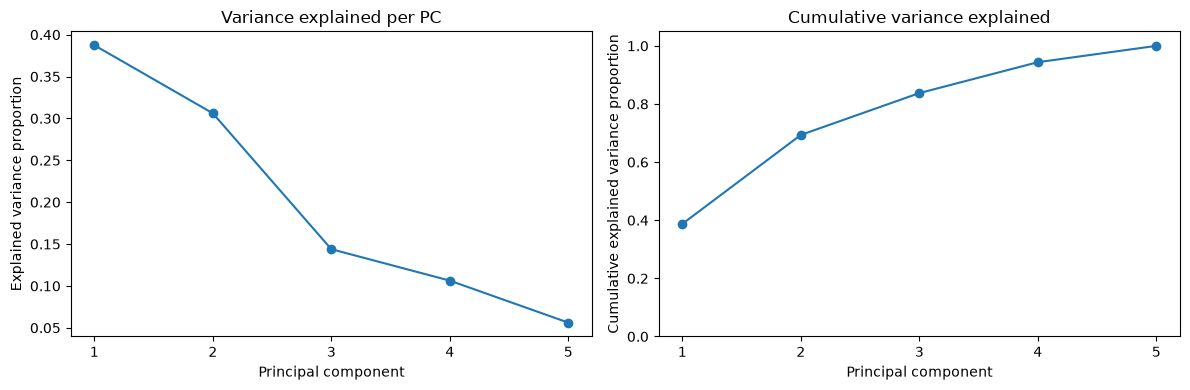

In [8]:
f, ax = plt.subplots(1, 2, figsize=(12, 4))
xdata = range(1, len(variance_props) + 1)

ax[0].plot(xdata, variance_props, marker='o')
ax[0].set_xticks(xdata)
ax[0].set_ylabel('Explained variance proportion')
ax[0].set_xlabel('Principal component')
ax[0].set_title('Variance explained per PC')

ax[1].plot(xdata, cumulative_variance, marker='o')
ax[1].set_xticks(xdata)
ax[1].set_ylim(0, 1.05)
ax[1].set_ylabel('Cumulative explained variance proportion')
ax[1].set_xlabel('Principal component')
ax[1].set_title('Cumulative variance explained')

plt.tight_layout()
plt.show()

### Question 1: Plot PC1 vs PC2

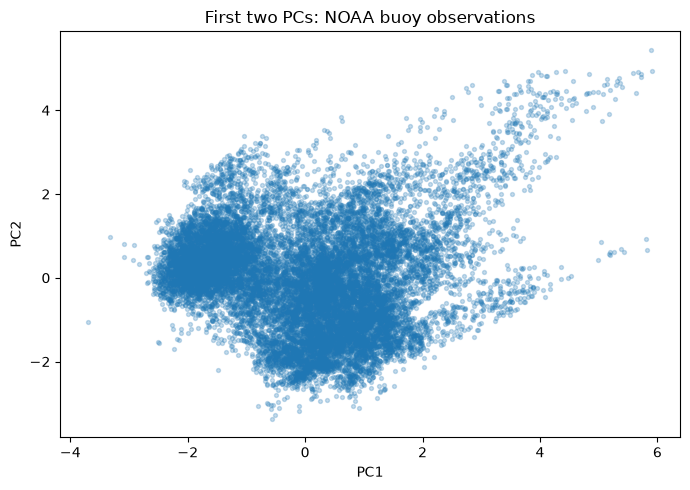

In [9]:
# PC2 vs PC1 
plt.subplots(figsize=(7, 5))
plt.scatter(waves_pca[:, 0], waves_pca[:, 1], s=8, alpha=0.25)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('First two PCs: NOAA buoy observations')
plt.tight_layout()
plt.show()

### Question 2: How many PCs capture most of the variability?

The first two PCs explain ~**70%** of the standardized variance. Three PCs explain ~**84%**, and four explain ~**94%**. In the elbow plot, the elbow seems to be in PC3 so I retain **3 PCs**. 

In [10]:
loadings = pd.DataFrame(pca.components_.T, index=wavesML.columns, columns=pc_names)
display(loadings.round(3))

num_pcs = 3

# for each PC, let's look at the top 3 vector components (loadings) that contribute to that PC.
for pc in range(num_pcs):
    ranked_loadings = np.argsort(np.abs(pca.components_[pc]))[::-1][:3]
    print(f"Top 3 loadings for PC{pc+1}:")
    print(wavesML.columns[ranked_loadings])
    print("\n")

,PC1,PC2,PC3,PC4,PC5
WVHT,0.541,0.195,0.376,0.704,0.177
DPD,-0.194,0.706,-0.274,-0.055,0.621
APD,0.322,0.621,0.232,-0.408,-0.539
MWD,0.567,-0.279,0.148,-0.566,0.509
WTMP,-0.494,0.021,0.841,-0.121,0.182


Top 3 loadings for PC1:
Index(['MWD', 'WVHT', 'WTMP'], dtype='str')


Top 3 loadings for PC2:
Index(['DPD', 'APD', 'MWD'], dtype='str')


Top 3 loadings for PC3:
Index(['WTMP', 'WVHT', 'DPD'], dtype='str')




### Question 4: What does PCA performance tell us about this dataset?

PCA simplifies this dataset somewhat: two PCs capture about 69% of the variation, while four are needed to capture over 90%. This means some variables share information, but two PCs cannot show all the important patterns.

### Clustering

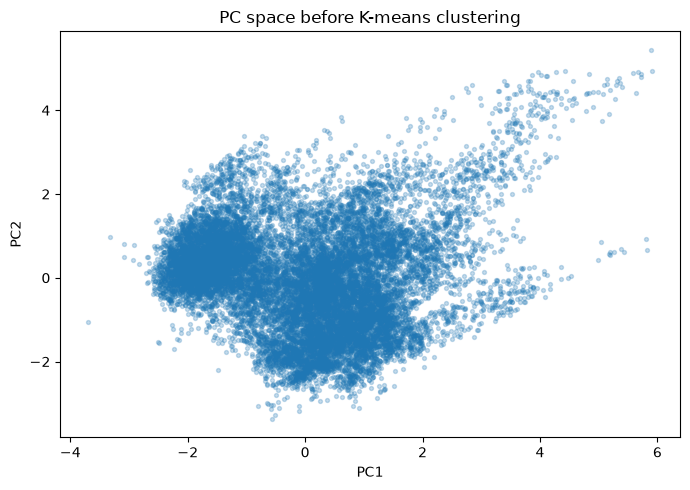

In [11]:
waves_reduced = waves_pca[:, :num_pcs]

plt.subplots(figsize=(7, 5))
plt.scatter(waves_reduced[:, 0], waves_reduced[:, 1], s=8, alpha=0.25)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PC space before K-means clustering')
plt.tight_layout()
plt.show()

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [13]:
cluster_numbers = range(1, 11)
sum_squared_distances = []
silhouette_scores = []

for k in cluster_numbers:
    kmeans = KMeans(n_clusters=k, random_state=38, n_init=20)
    cluster_labels = kmeans.fit_predict(waves_reduced)
    sum_squared_distances.append(kmeans.inertia_)

    if k > 1:
        score = silhouette_score(waves_reduced, cluster_labels,
                                 sample_size=2000, random_state=38)
        silhouette_scores.append(score)
    else:
        silhouette_scores.append(np.nan)

cluster_results = pd.DataFrame({
    'K': list(cluster_numbers),
    'Sum of squared distances': sum_squared_distances,
    'Sample silhouette score': silhouette_scores
})
cluster_results['Inertia decrease (%)'] = -cluster_results['Sum of squared distances'].pct_change() * 100
cluster_results.round(3)

,K,Sum of squared distances,Sample silhouette score,Inertia decrease (%)
0,1,72338.484,NaN,NaN
1,2,48028.975,0.341,33.605
2,3,33188.195,0.370,30.900
3,4,26722.366,0.355,19.482
4,5,22542.602,0.357,15.641
5,6,20098.902,0.303,10.840
6,7,17805.966,0.329,11.408
7,8,15932.470,0.335,10.522
8,9,14355.994,0.316,9.895
9,10,13141.125,0.306,8.462


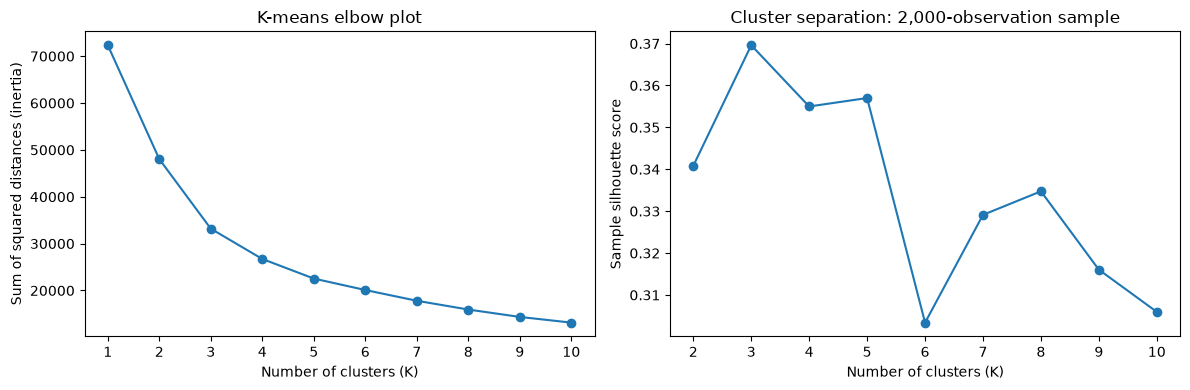

In [14]:
f, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(cluster_numbers, sum_squared_distances, marker='o')
ax[0].set_xticks(list(cluster_numbers))
ax[0].set_xlabel('Number of clusters (K)')
ax[0].set_ylabel('Sum of squared distances (inertia)')
ax[0].set_title('K-means elbow plot')

ax[1].plot(list(cluster_numbers)[1:], silhouette_scores[1:], marker='o')
ax[1].set_xticks(list(cluster_numbers)[1:])
ax[1].set_xlabel('Number of clusters (K)')
ax[1].set_ylabel('Sample silhouette score')
ax[1].set_title('Cluster separation: 2,000-observation sample')

plt.tight_layout()
plt.show()

### Question 7: How many clusters are the right choice, and why?

I choose **K = 3** because it gives a simple grouping and substantially reduces inertia. The elbow is gradual, so three clusters are a reasonable choice, although the groups still overlap.

### Question 8: Plot PC1 vs PC2 with cluster centers

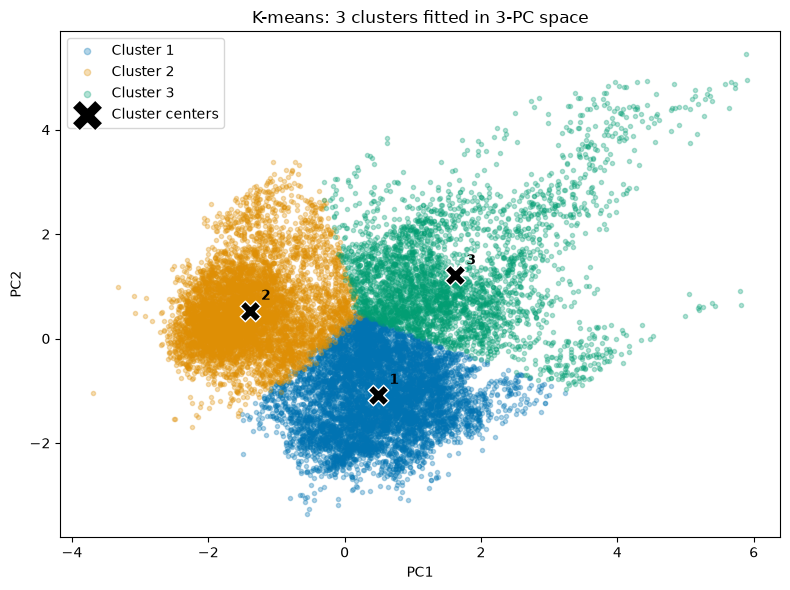

In [15]:
best_k = 3
kmeans = KMeans(n_clusters=best_k, random_state=38, n_init=20)
cluster_labels = kmeans.fit_predict(waves_reduced)
cluster_centers = kmeans.cluster_centers_

plt.subplots(figsize=(8, 6))
colors = sns.color_palette('colorblind', best_k)
for cluster in range(best_k):
    selected = cluster_labels == cluster
    plt.scatter(waves_reduced[selected, 0], waves_reduced[selected, 1],
                s=9, alpha=0.30, color=colors[cluster], label=f'Cluster {cluster + 1}')

plt.scatter(cluster_centers[:, 0], cluster_centers[:, 1],
            s=220, marker='X', c='black', edgecolors='white',
            linewidths=1, label='Cluster centers', zorder=5)
for cluster in range(best_k):
    plt.annotate(str(cluster + 1), cluster_centers[cluster, :2],
                 xytext=(8, 8), textcoords='offset points', fontweight='bold')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'K-means: {best_k} clusters fitted in {num_pcs}-PC space')
plt.legend(markerscale=1.5)
plt.tight_layout()
plt.show()


### Question 9: Does this clustering make sense visually?


Yes, the three clusters occupy different parts of the plot, but their edges overlap. Some overlap may occur because clustering uses PC1–PC3, while the plot shows only PC1 and PC2. The groups suggest broad patterns rather than completely separate conditions.